# 06 - Baselines and single-modality models

QoL: 5-fold participant-grouped CV x 5 repeats, nested tuning. MMASH: leave-one-subject-out.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
M = ROOT / 'results' / 'metrics'; F = ROOT / 'results' / 'figures'; P = ROOT / 'data' / 'processed'
s = pd.read_csv(M/'qol_cv_summary.csv')
cols = ['experiment','roc_auc_mean','roc_auc_sd','roc_auc_ci_low','roc_auc_ci_high','balanced_accuracy_mean','macro_f1_mean','pairwise_accuracy_mean']
s[s.strategy.isin(['single']) | s.experiment.str.startswith('Baseline')][cols].round(3)

,experiment,roc_auc_mean,roc_auc_sd,roc_auc_ci_low,roc_auc_ci_high,balanced_accuracy_mean,macro_f1_mean,pairwise_accuracy_mean
21,EDA | single | random_forest,0.682,0.133,0.630,0.735,0.656,0.651,0.724
22,HR | single | logreg,0.680,0.090,0.644,0.715,0.647,0.632,0.676
25,EDA | single | xgboost,0.676,0.122,0.628,0.724,0.653,0.648,0.680
29,HR | single | random_forest,0.670,0.096,0.632,0.707,0.607,0.592,0.702
30,EDA | single | gradient_boosting,0.669,0.126,0.620,0.719,0.631,0.623,0.693
32,EDA | single | logreg,0.665,0.091,0.629,0.701,0.598,0.587,0.804
34,HR | single | svm_rbf,0.663,0.102,0.623,0.703,0.629,0.610,0.658
39,HR | single | xgboost,0.660,0.101,0.620,0.699,0.616,0.604,0.671
43,EDA | single | svm_rbf,0.642,0.089,0.608,0.677,0.587,0.565,0.764
44,HR | single | gradient_boosting,0.640,0.105,0.599,0.681,0.600,0.591,0.662


## MMASH sleep efficiency (LOSO)

In [2]:
r = pd.read_csv(M/'mmash_loso_results.csv'); r[r.target=='sleep_efficiency'].sort_values('mae').round(3)

,target,modalities,strategy,model,n,n_features,mae,rmse,r2,mae_gain_vs_mean,mae_gain_ci_low,mae_gain_ci_high,perm_p_value,perm_null_median_mae
13,sleep_efficiency,Behav+Psych,early,random_forest,21,14,5.424,6.572,0.007,0.616,-0.554,1.718,0.090,6.405
3,sleep_efficiency,Behav,single,random_forest,21,7,5.517,6.264,0.098,0.523,-0.754,1.743,0.090,6.346
16,sleep_efficiency,Phys+Behav+Psych,early,random_forest,21,19,5.691,6.783,-0.058,0.349,-0.670,1.366,0.174,6.404
7,sleep_efficiency,Phys+Behav,early,random_forest,21,12,5.815,6.622,-0.008,0.225,-0.806,1.222,0.199,6.409
18,sleep_efficiency,none,baseline,dummy_mean,21,0,6.040,6.925,-0.102,0.000,NaN,NaN,NaN,NaN
5,sleep_efficiency,Psych,single,random_forest,21,7,6.113,7.093,-0.157,-0.073,-1.100,0.910,NaN,NaN
0,sleep_efficiency,Phys,single,ridge,21,5,6.125,7.054,-0.144,-0.085,-0.271,0.021,0.451,6.156
6,sleep_efficiency,Phys+Behav,early,ridge,21,12,6.202,7.142,-0.173,-0.162,-0.460,0.053,0.487,6.225
15,sleep_efficiency,Phys+Behav+Psych,early,ridge,21,19,6.204,7.209,-0.195,-0.164,-0.467,0.065,0.392,6.394
8,sleep_efficiency,Phys+Behav,late,ridge,21,12,6.223,7.145,-0.174,-0.183,-0.403,-0.011,0.557,6.184


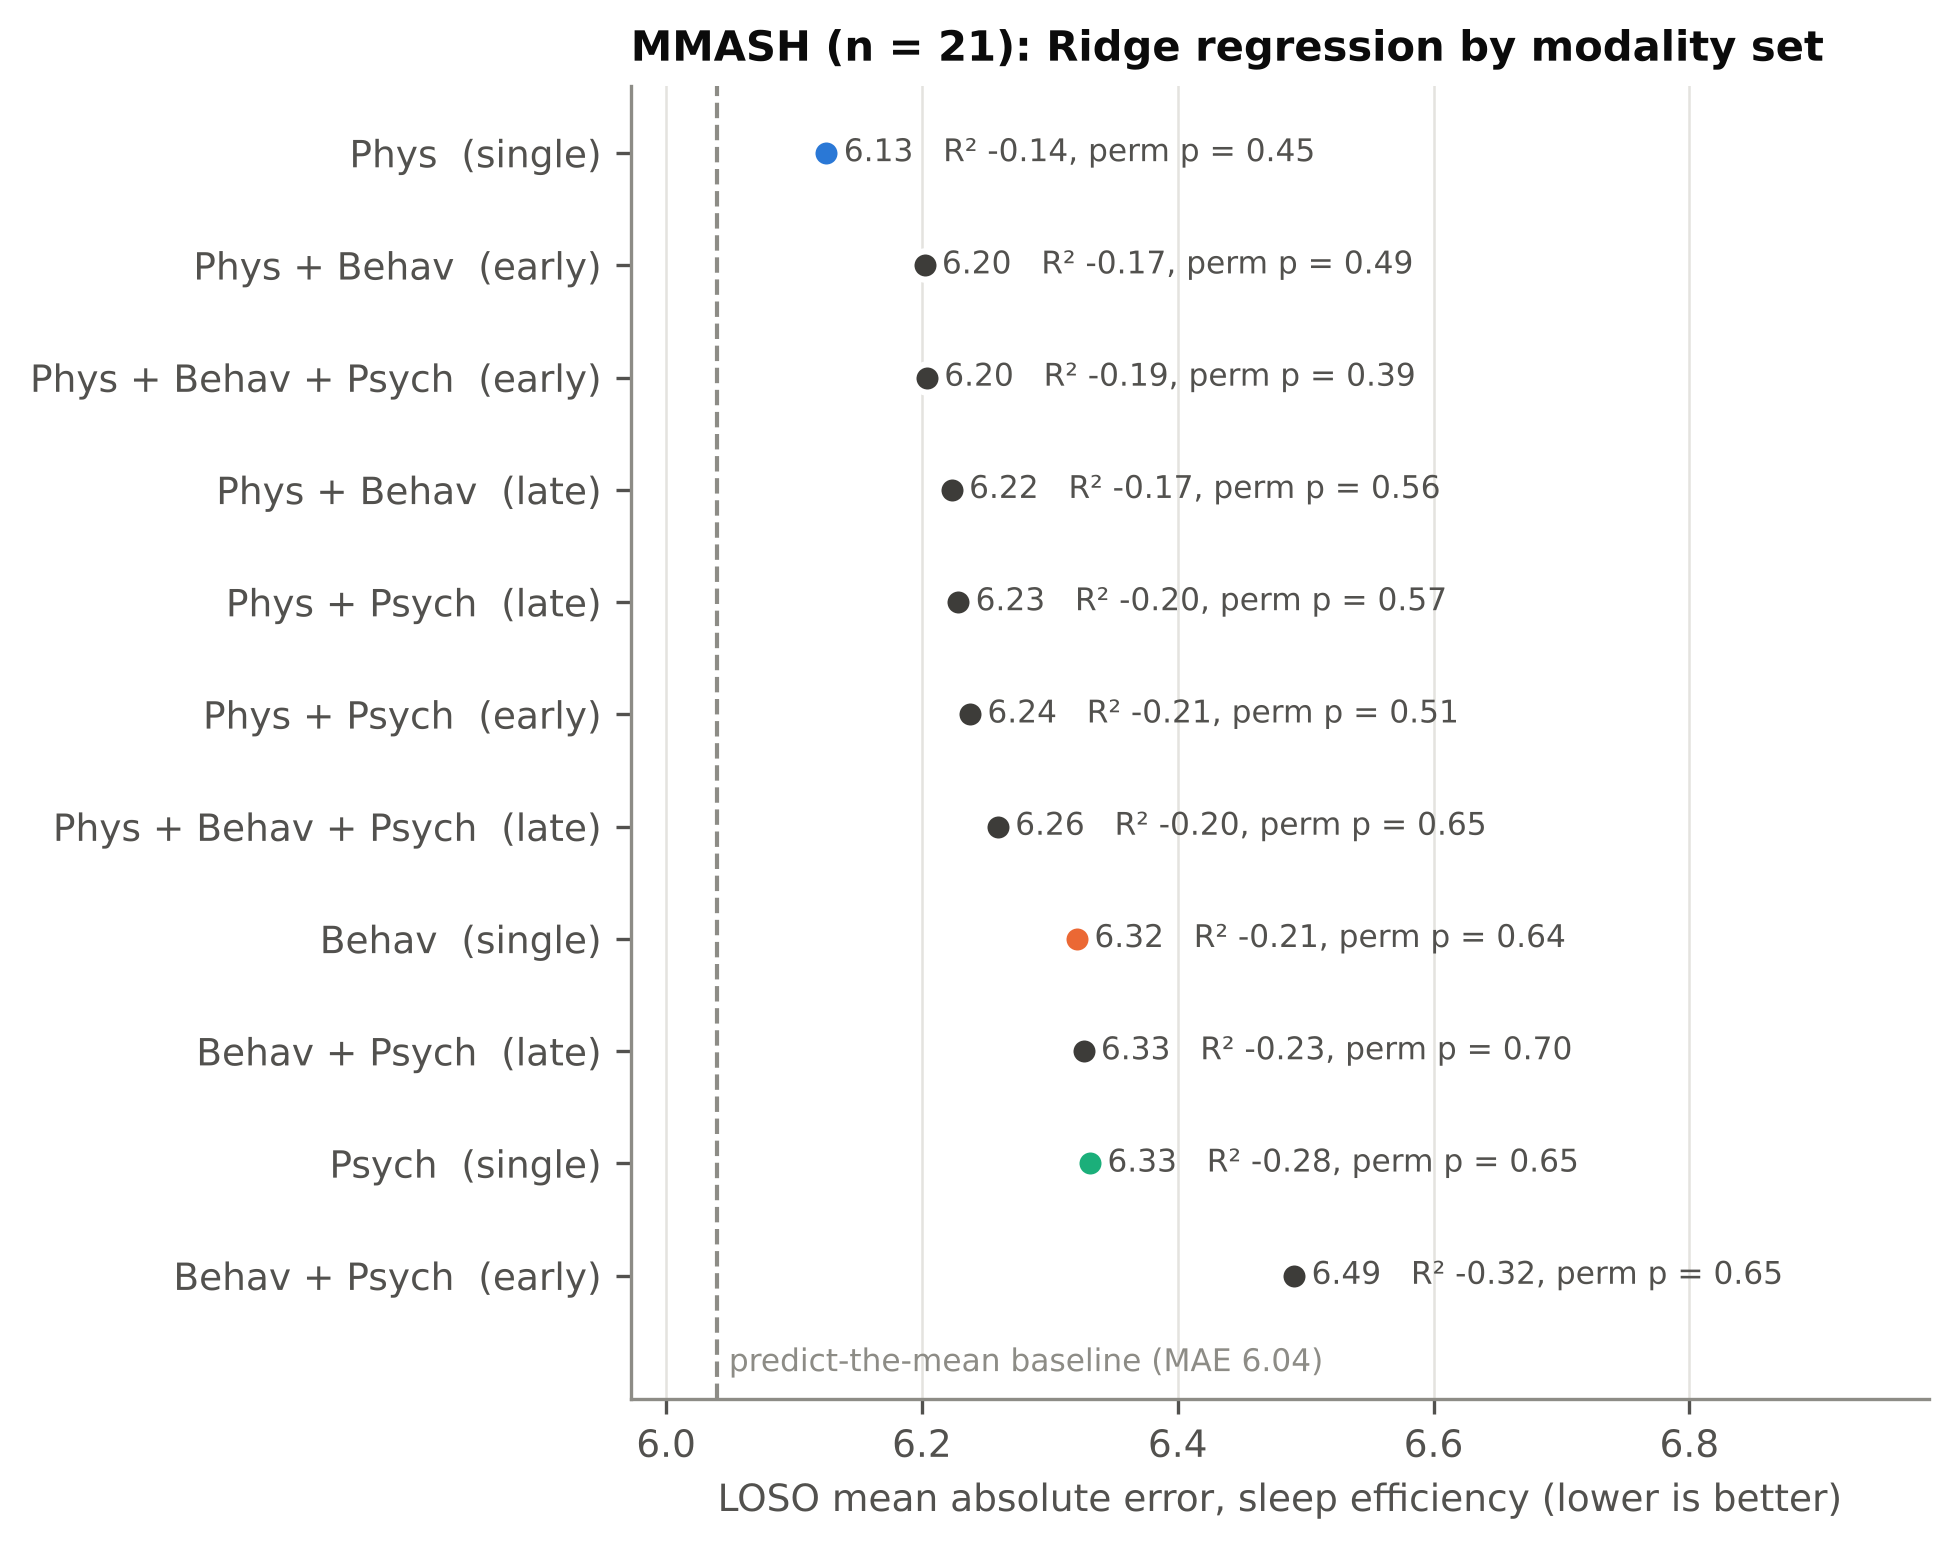

In [3]:
display(Image(F/'mmash_loso_sleep_efficiency.png', width=650))